# Two radar bands and an incidence angle: rebuilding the Iceberg CNN

This walkthrough follows the original multi-input method and explains its data, split,
architecture and artifact decisions. The default is a **bounded real-data run**: 128 training
records, the original holdout, one epoch and one pass through training data.

That verifies a runnable method port. It does not reproduce the historical leaderboard score
or establish numerical equality with the 2017 Keras model.
See [the migration rationale](../docs/migration.md).

**Prerequisites:** the locked project environment and authorized competition files. Set
`ICEBERG_DATA_DIR` to their directory. Run all cells in order;
keep data and run artifacts outside Git.

## 1. Resolve the environment before interpreting a result

The same package drives the notebook and CLI. We make paths and configuration visible;
changing an epoch count or training subset changes the experiment, not only its presentation.

In [1]:
import csv
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sklearn.model_selection import StratifiedShuffleSplit

from iceberg.data import load_data
from iceberg.runtime import evaluate, predict, train

PROJECT = Path.cwd()
if not (PROJECT / "pyproject.toml").exists():
    PROJECT = PROJECT.parent
DATA_DIR = Path(os.environ.get("ICEBERG_DATA_DIR", PROJECT / "input"))
CONFIG = json.loads((PROJECT / "configs/bounded.json").read_text())
RUN_ROOT = Path(os.environ.get("ICEBERG_RUN_DIR", PROJECT / ".local/notebook-runs"))
RUN_DIR = RUN_ROOT / datetime.now(UTC).strftime("%Y%m%dT%H%M%S%f")
assert (DATA_DIR / "train.json").is_file(), "Download data and set ICEBERG_DATA_DIR first"
plt.rcParams.update({"figure.figsize": (8, 3.5), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
print(json.dumps(CONFIG, indent=2))

{
  "name": "bounded-real-data",
  "seed": 1017,
  "split_seed": 25,
  "validation_fraction": 0.159,
  "filters": 8,
  "hidden": 128,
  "batch_size": 16,
  "epochs": 1,
  "epoch_repeats": 1,
  "learning_rate": 0.0005,
  "learning_rate_decay": 0.002,
  "augment": true,
  "max_train_rows": 128,
  "threads": 4
}


## 2. Inspect the two data modalities

Each observation contains two 75×75 radar bands and one incidence angle. Keep both channels:
they measure different polarizations of the same scene. The original rescaling is `x / 100 + 0.5`.
It is a fixed transform, not a fitted normalizer.
The string `na` becomes the original `-1` angle sentinel.

Before training, inspect shapes, target balance and missing metadata. Raw competition rows
and radar pixels are not embedded in this notebook's saved outputs.

{'records': 1604, 'radar_shape': (1604, 2, 75, 75), 'iceberg_fraction': 0.469451367855072, 'missing_angles': 133}


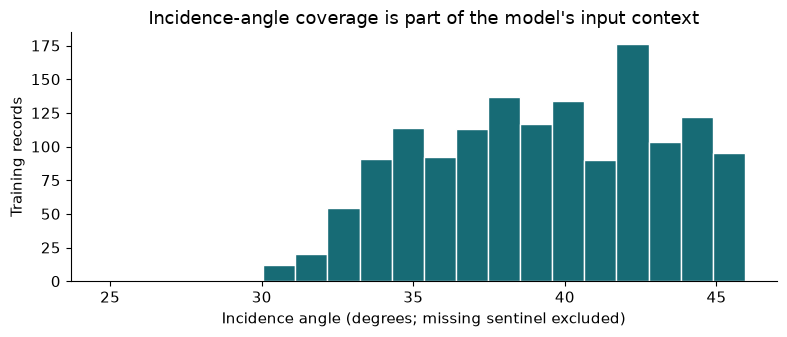

In [2]:
data = load_data(DATA_DIR / "train.json", labeled=True)
print({"records": len(data.ids), "radar_shape": data.images.shape,
       "iceberg_fraction": float(data.targets.mean()),
       "missing_angles": int((data.angles[:, 0] == -1).sum())})
observed_angles = data.angles[data.angles[:, 0] != -1, 0]
fig, ax = plt.subplots()
ax.hist(observed_angles, bins=20, color="#176b75", edgecolor="white")
ax.set(title="Incidence-angle coverage is part of the model's input context",
       xlabel="Incidence angle (degrees; missing sentinel excluded)", ylabel="Training records")
fig.tight_layout()
plt.show()

**Interpretation.** The histogram describes the observed angle coverage;
it does not show
which angles cause errors. A useful follow-up is to inspect holdout error by angle availability.
Replacing `-1` with learned imputation would be a new preprocessing experiment
and should be labeled.

## 3. Preserve the validation question

Use the original stratified split: seed 25 and a 15.9% holdout. The bounded profile reduces
only the training portion after that split, keeping the holdout intact. Predictions on the
training set are a diagnostic, not held-out validation.

In [3]:
reference_split = StratifiedShuffleSplit(n_splits=1, test_size=0.159, random_state=25)
train_indices, validation_indices = next(reference_split.split(data.images, data.targets))
assert not set(train_indices) & set(validation_indices)
print({"reference_training_rows": len(train_indices), "holdout_rows": len(validation_indices),
       "bounded_training_limit": CONFIG["max_train_rows"]})

{'reference_training_rows': 1348, 'holdout_rows': 256, 'bounded_training_limit': 128}


## 4. Map the original architecture before changing it

```text
two radar channels ──┬─ pooled convolution branch ───────┐
                    └─ full-resolution conv branch ────┼─ dense blocks → iceberg probability
incidence angle ─────── normalization ───────────────────┘
```

Both branches retain the original depths, widths, ELU activations and pooling choices.
Batch normalization explicitly follows the original momentum-zero/population-variance convention.
Spatial augmentation applies the same geometry to both bands. The original fixed zoom factor
0.1 is preserved and documented even though it is unusually aggressive.

The output uses logits during training and sigmoid for probabilities. The optimizer's old
`decay` argument is mapped to learning-rate decay, not L2 weight decay.

## 5. Train a bounded recipe and retain its evidence

This call creates a fresh run directory. It saves the chosen configuration, input checksum,
split roles, training history, best checkpoint and held-out predictions. A failed run retains
its failed status. No private tracking service is required to complete the local run.

In [4]:
manifest = train(DATA_DIR / "train.json", RUN_DIR, CONFIG)
metrics = json.loads((RUN_DIR / "metrics.json").read_text())
display(Markdown(
    f"**Observed held-out log loss: {metrics['validation_log_loss']:.4f}.** "
    f"Training used {manifest['train_rows']} records and evaluation used "
    f"{manifest['validation_rows']} untouched holdout records. "
    "This is bounded-run evidence; it is not a historical leaderboard comparison."
))

{"epoch": 1, "training_batch_loss_mean": 1.0097075924277306, "validation_log_loss": 0.8497995872496394}


**Observed held-out log loss: 0.8498.** Training used 128 records and evaluation used 256 untouched holdout records. This is bounded-run evidence; it is not a historical leaderboard comparison.

## 6. Reload the checkpoint and inspect errors

Evaluation reconstructs the model in a separate call, verifies the training-file checksum,
and uses the checkpoint's saved holdout indices. A fresh CLI process exercises the same
path in the reproduction instructions. Histogram separation can help diagnose the predictions;
it does not replace log loss or establish calibration.

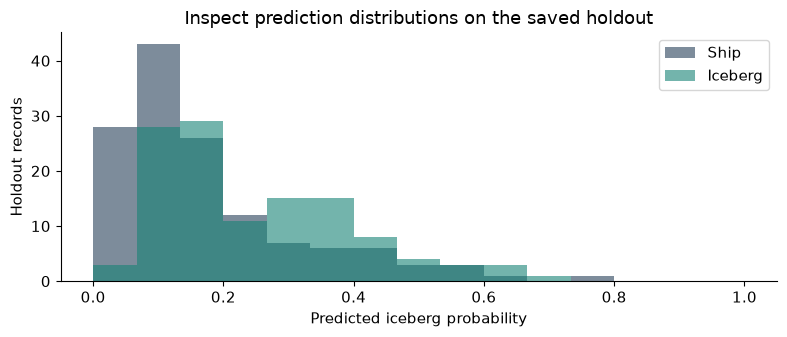

In [5]:
reloaded = evaluate(RUN_DIR / "model.pt", DATA_DIR / "train.json")
assert abs(reloaded["validation_log_loss"] - metrics["validation_log_loss"]) < 1e-12
with (RUN_DIR / "validation.csv").open() as stream:
    validation_rows = list(csv.DictReader(stream))
fig, ax = plt.subplots()
for target, label, color in [(0, "Ship", "#263f59"), (1, "Iceberg", "#168376")]:
    values = [float(row["probability"]) for row in validation_rows if int(row["target"]) == target]
    ax.hist(values, bins=np.linspace(0, 1, 16), alpha=0.6, label=label, color=color)
ax.set(title="Inspect prediction distributions on the saved holdout",
       xlabel="Predicted iceberg probability", ylabel="Holdout records")
ax.legend()
fig.tight_layout()
plt.show()

**Try one controlled change.** Copy the bounded configuration, change one factor
(for example, disable augmentation), and use a new run directory with the same split.
Compare log loss and error patterns. A change that improves one short run is a hypothesis
for further testing; do not claim a general improvement from it alone.

## 7. Generate predictions through the same saved model

Set `ICEBERG_FULL_TEST=1` to run inference over the full authorized test file. This takes
longer than the teaching training profile. Output IDs and order come from the input file;
the CLI also writes a checksum receipt. Creating the file does not submit it to Kaggle.

In [6]:
if os.environ.get("ICEBERG_FULL_TEST", "0") == "1":
    prediction_receipt = predict(RUN_DIR / "model.pt", DATA_DIR / "test.json",
                                 RUN_DIR / "submission.csv")
    print(prediction_receipt)
else:
    print("Full-test inference not requested. Set ICEBERG_FULL_TEST=1 or use the predict CLI.")

{'rows': 8424, 'input_sha256': 'b1334a65bd0ceb9a027c780ba222f1dfba4cc34bd6adffef2ef5ed0e22a002fd', 'checkpoint_sha256': 'a302d8ded200e28981dc016f8a47ae163478f5c7e61b2f087bcea2433c3cd968', 'output_sha256': '4b43d153202a83a0ff811753b70be5f99d9a532cbce86ece1b204f9c39fe3fc3', 'checkpoint_profile': 'bounded-real-data', 'status': 'model_predictions'}


## 8. Connect the run to existing MLOps services

The run directory is the local evidence boundary. The optional `iceberg track` command logs
a completed run to an existing MLflow deployment and checks the artifact hashes first.
MLflow can proxy those artifacts to the existing SeaweedFS store. The project deploys no servers.

Docker JupyterLab mounts project files, datasets and working outputs. An optional Compose
override makes an existing client-side SeaweedFS filesystem mount visible at `/shared`.
Prefect and W&B adapters remain future extensions; they are not claimed as implemented here.

For Kaggle, the thin notebook installs the project wheel from an attached code dataset,
uses Kaggle-mounted competition data, and saves a portable run bundle. Kaggle execution
is a separate verification target and does not require private service access.

See [reproduction](../docs/reproduction.md), [migration rationale](../docs/migration.md),
[MLOps boundaries](../docs/mlops.md), and [observed results](../docs/results.md).